
KNN Performance across K and Distance Metrics:
 K  Euclidean Accuracy  Manhattan Accuracy
 1            0.932639            0.932154
 3            0.942331            0.941846
 5            0.946935            0.944996
 7            0.947904            0.948873
 9            0.947904            0.947419
11            0.952023            0.948146
15            0.950085            0.948873
21            0.952508            0.952992

Optimal K identified: 21 (Euclidean Accuracy: 0.9525)

Classification Report for Best KNN Model:
              precision    recall  f1-score   support

      Normal       0.97      0.98      0.97      3507
Failure Soon       0.86      0.81      0.84       620

    accuracy                           0.95      4127
   macro avg       0.92      0.89      0.90      4127
weighted avg       0.95      0.95      0.95      4127


Experiment 9 Completed Successfully


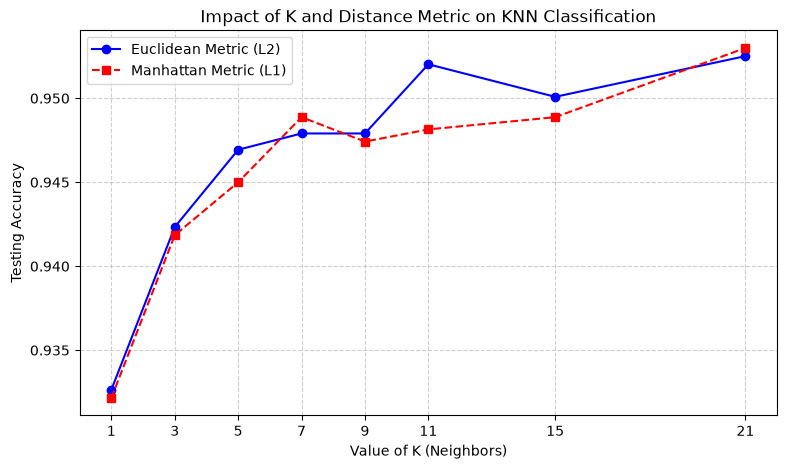

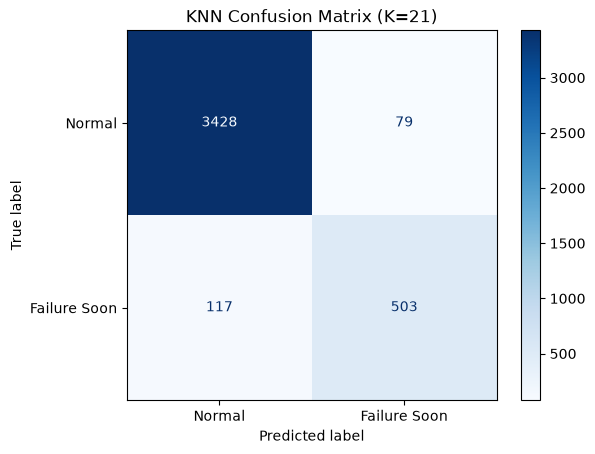

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]
df["failure_soon"] = (df["RUL"] <= 30).astype(int)

features = ["cycle", "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]
X = df[features]
y = df["failure_soon"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Analyze the impact of different K values and distance metrics
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
euclidean_acc = []
manhattan_acc = []

for k in k_values:
    # Euclidean distance (p=2)
    knn_euc = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    knn_euc.fit(X_train_scaled, y_train)
    euclidean_acc.append(accuracy_score(y_test, knn_euc.predict(X_test_scaled)))
    
    # Manhattan distance (p=1)
    knn_man = KNeighborsClassifier(n_neighbors=k, metric="manhattan")
    knn_man.fit(X_train_scaled, y_train)
    manhattan_acc.append(accuracy_score(y_test, knn_man.predict(X_test_scaled)))

knn_results = pd.DataFrame({
    "K": k_values,
    "Euclidean Accuracy": euclidean_acc,
    "Manhattan Accuracy": manhattan_acc
})
print("\nKNN Performance across K and Distance Metrics:")
print(knn_results.to_string(index=False))

# Plot K vs Accuracy for both distance metrics
plt.figure(figsize=(9, 5))
plt.plot(k_values, euclidean_acc, marker="o", color="blue", label="Euclidean Metric (L2)")
plt.plot(k_values, manhattan_acc, marker="s", color="red", linestyle="--", label="Manhattan Metric (L1)")
plt.xlabel("Value of K (Neighbors)")
plt.ylabel("Testing Accuracy")
plt.title("Impact of K and Distance Metric on KNN Classification")
plt.xticks(k_values)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

# 2. Optimal KNN Model Evaluation
best_k = k_values[np.argmax(euclidean_acc)]
print(f"\nOptimal K identified: {best_k} (Euclidean Accuracy: {max(euclidean_acc):.4f})")

best_knn = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean")
best_knn.fit(X_train_scaled, y_train)
y_pred_knn = best_knn.predict(X_test_scaled)

print("\nClassification Report for Best KNN Model:")
print(classification_report(y_test, y_pred_knn, target_names=["Normal", "Failure Soon"]))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Failure Soon"])
disp.plot(cmap="Blues")
plt.title(f"KNN Confusion Matrix (K={best_k})")
plt.show()

print("Experiment 9 Completed Successfully")